In [4]:
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error,mean_squared_error,root_mean_squared_error,r2_score
from sklearn.tree import DecisionTreeClassifier
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt

In [6]:
df = pd.read_csv(r"C:\Users\Admin\Downloads\massive_employee_practice_dataset.csv")

In [9]:
df.shape

(10120, 20)

In [10]:
df.columns

Index(['Employee_ID', 'Full_Name', 'Age', 'Gender', 'Department', 'Job_Title',
       'City', 'Education', 'Salary', 'Bonus', 'Joining_Date',
       'Experience_Years', 'Performance_Rating', 'Projects_Completed',
       'Remote_Work', 'Employment_Status', 'Email', 'Overtime_Hours',
       'Monthly_Sales', 'Last_Review_Date'],
      dtype='object')

In [11]:
df.head()

,Employee_ID,Full_Name,Age,Gender,Department,Job_Title,City,Education,Salary,Bonus,Joining_Date,Experience_Years,Performance_Rating,Projects_Completed,Remote_Work,Employment_Status,Email,Overtime_Hours,Monthly_Sales,Last_Review_Date
0,EMP13360,Ananya Patil,45.0,Male,HR,Developer,Pune,Master's,68660.0,8601.0,12-11-2019,13.1,2,17,Hybrid,Resigned,employee3360@example.com,30.9,13306.58,2025-04-02
1,EMP19369,Ananya Patil,34.0,FEMALE,FINANCE,Developer,Delhi,Bachelor's,15629.0,699.0,07-22-2022,18.8,NaN,0,Yes,INACTIVE,employee9369@example.com,33.3,30004.81,2025-03-10
2,EMP16895,Sneha Deshmukh,38.0,F,it,Team Lead,Bengaluru,bachelor's,40849.0,3401.0,2024-04-08,2.7,3,5,Yes,Resigned,employee6895@example.com,13.4,NaN,2026-06-04
3,EMP15214,Vikram Patil,31.0,Female,FINANCE,Team Lead,Mumbai,High School,37201.0,819.0,12/08/2023,11.1,4,30,No,Active,employee5214@example.com,20.9,NaN,2026-10-05
4,EMP17380,Ananya Kulkarni,25.0,F,Support,Support Engineer,Nagpur,Diploma,51566.0,1997.0,07/10/2025,14.7,1,29,Yes,On Leave,employee7380@example.com,33.2,224435.73,2026-06-29


In [12]:
df.tail()

,Employee_ID,Full_Name,Age,Gender,Department,Job_Title,City,Education,Salary,Bonus,Joining_Date,Experience_Years,Performance_Rating,Projects_Completed,Remote_Work,Employment_Status,Email,Overtime_Hours,Monthly_Sales,Last_Review_Date
10115,EMP17891,Vikram Kulkarni,28.0,NaN,FINANCE,Intern,pune,Bachelor's,44946.0,4892.0,08-27-2020,23.1,3,8,no,Resigned,employee7891@example.com,19.9,210149.96,2025-02-07
10116,EMP11769,Karan Khan,37.0,Female,Finance,Analyst,Bengaluru,Master's,32351.0,681.0,04-05-2021,11.2,1,35,YES,Inactive,employee1769@example.com,21.8,168354.49,2026-03-24
10117,EMP19930,Rohan Sharma,19.0,Female,it,Developer,Bengaluru,PhD,40561.0,6836.0,13/08/2020,20.4,3,23,Hybrid,Resigned,employee9930@example.com,12.8,16870.06,2025-11-28
10118,EMP13241,Priya Sharma,37.0,F,HR,Intern,Bengaluru,Masters,18723.0,1981.0,05/01/2023,20.2,NaN,6,Yes,active,employee3241@example.com,7.7,98041.70,2025-11-28
10119,EMP17204,Rohan Deshmukh,34.0,F,it,Accountant,Nashik,Masters,26205.0,4572.0,04/02/2026,24.2,1,31,no,On Leave,employee7204@example.com,24.5,NaN,2026-05-20


In [16]:
df["Education"].value_counts()

Education
Bachelor's     2748
Master's       1435
High school    1405
Masters        1397
Diploma        1394
Phd            1341
Name: count, dtype: int64

In [15]:
df["Education"] = df["Education"].str.capitalize()

In [20]:
df["Full_Name"].apply(lambda x:x.split()[0::-1]).head()

0    [Ananya]
1    [Ananya]
2     [Sneha]
3    [Vikram]
4    [Ananya]
Name: Full_Name, dtype: object

In [22]:
df.duplicated().sum()

np.int64(120)

In [23]:
df.drop_duplicates(inplace=True)

In [24]:
df.shape

(10000, 20)

In [25]:
df.isna().sum()

Employee_ID              0
Full_Name                0
Age                    237
Gender                 386
Department             323
Job_Title                0
City                   336
Education              394
Salary                 228
Bonus                  392
Joining_Date           255
Experience_Years         0
Performance_Rating    1712
Projects_Completed       0
Remote_Work              0
Employment_Status        0
Email                  175
Overtime_Hours           0
Monthly_Sales         4525
Last_Review_Date         0
dtype: int64

In [27]:
df["Age"] = pd.to_numeric(df["Age"],errors="raise")

ValueError: Unable to parse string "34 years" at position 24

In [41]:
df["Age"] = df["Age"].astype("Int64")

ValueError: invalid literal for int() with base 10: '45.0'

In [38]:
df.loc[24]

Employee_ID                           EMP14323
Full_Name                         Ananya Joshi
Age                                   34 years
Gender                                    Male
Department                                  HR
Job_Title                              Manager
City                                    Nagpur
Education                           Bachelor's
Salary                                 19213.0
Bonus                                    920.0
Joining_Date                        2022-05-06
Experience_Years                          15.0
Performance_Rating                           1
Projects_Completed                          27
Remote_Work                             Hybrid
Employment_Status                       Active
Email                 employee4323@example.com
Overtime_Hours                            10.0
Monthly_Sales                              NaN
Last_Review_Date                    2025-05-03
Name: 24, dtype: object

In [42]:
df["Age"] = df["Age"].str.replace(" years", "", regex=False)

df["Age"] = pd.to_numeric(df["Age"], errors="coerce")

In [43]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 10000 entries, 0 to 10119
Data columns (total 20 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Employee_ID         10000 non-null  object 
 1   Full_Name           10000 non-null  object 
 2   Age                 9763 non-null   float64
 3   Gender              9614 non-null   object 
 4   Department          9677 non-null   object 
 5   Job_Title           10000 non-null  object 
 6   City                9664 non-null   object 
 7   Education           9606 non-null   object 
 8   Salary              9772 non-null   object 
 9   Bonus               9608 non-null   float64
 10  Joining_Date        9745 non-null   object 
 11  Experience_Years    10000 non-null  float64
 12  Performance_Rating  8288 non-null   object 
 13  Projects_Completed  10000 non-null  int64  
 14  Remote_Work         10000 non-null  object 
 15  Employment_Status   10000 non-null  object 
 16  Email    

In [44]:
df["Age"] = df["Age"].fillna(df["Age"].mean())

In [45]:
df.isna().sum()

Employee_ID              0
Full_Name                0
Age                      0
Gender                 386
Department             323
Job_Title                0
City                   336
Education              394
Salary                 228
Bonus                  392
Joining_Date           255
Experience_Years         0
Performance_Rating    1712
Projects_Completed       0
Remote_Work              0
Employment_Status        0
Email                  175
Overtime_Hours           0
Monthly_Sales         4525
Last_Review_Date         0
dtype: int64

In [47]:
df["Gender"] = df["Gender"].fillna(df["Gender"].mode()[0])

In [49]:
df["Gender"].value_counts()

Gender
Other     1805
Female    1414
Male      1371
male      1368
F         1366
M         1361
FEMALE    1315
Name: count, dtype: int64

In [51]:
df.loc[df["Gender"]=="M","Gender"]="Male"
df.loc[df["Gender"]=="F","Gender"]="Female"
df.loc["Gender"] = df["Gender"].str.lower()

In [55]:
df["Gender"].value_counts()

Gender
Female    4095
Male      2732
Other     1805
male      1368
Name: count, dtype: int64

In [54]:
df.loc[df["Gender"]=="FEMALE","Gender"]="Female"

In [56]:
df["Gender"] = df["Gender"].str.capitalize()

In [57]:
df["Gender"].value_counts()

Gender
Male      4100
Female    4095
Other     1805
Name: count, dtype: int64

In [60]:
df["Age"] = pd.to_numeric(df["Age"])

In [63]:
df["Age"] = df["Age"].astype("int64")

IntCastingNaNError: Cannot convert non-finite values (NA or inf) to integer

In [64]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 10001 entries, 0 to Gender
Data columns (total 20 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Employee_ID         10000 non-null  object 
 1   Full_Name           10000 non-null  object 
 2   Age                 10000 non-null  float64
 3   Gender              10000 non-null  object 
 4   Department          9677 non-null   object 
 5   Job_Title           10000 non-null  object 
 6   City                9664 non-null   object 
 7   Education           9606 non-null   object 
 8   Salary              9772 non-null   object 
 9   Bonus               9608 non-null   float64
 10  Joining_Date        9745 non-null   object 
 11  Experience_Years    10000 non-null  float64
 12  Performance_Rating  8288 non-null   object 
 13  Projects_Completed  10000 non-null  float64
 14  Remote_Work         10000 non-null  object 
 15  Employment_Status   10000 non-null  object 
 16  Email   

In [66]:
# df[df["Department"].isna()]\
df["Department"].value_counts()

Department
IT            1064
FINANCE       1033
Marketing      992
HR             974
Finance        962
HR             955
it             942
Sales          895
Support        893
Operations     869
MARKETING       31
SUPPORT         24
SALES           24
OPERATIONS      19
Name: count, dtype: int64

In [67]:
df["Department"] = df["Department"].fillna(df["Department"].mode()[0])

In [68]:
df.loc[14]

Employee_ID                           EMP11430
Full_Name                          Isha Sharma
Age                                       41.0
Gender                                   Other
Department                                  IT
Job_Title                            Executive
City                                     Dhule
Education                           Bachelor's
Salary                                 50886.0
Bonus                                   3075.0
Joining_Date                        25/07/2020
Experience_Years                           6.9
Performance_Rating                           2
Projects_Completed                        23.0
Remote_Work                                 no
Employment_Status                     On Leave
Email                 employee1430@example.com
Overtime_Hours                            23.2
Monthly_Sales                         89399.53
Last_Review_Date                    2025-04-28
Name: 14, dtype: object

In [69]:
df["Department"].value_counts()

Department
IT            1388
FINANCE       1033
Marketing      992
HR             974
Finance        962
HR             955
it             942
Sales          895
Support        893
Operations     869
MARKETING       31
SUPPORT         24
SALES           24
OPERATIONS      19
Name: count, dtype: int64

In [70]:
df["Department"] = df["Department"].str.lower()

In [72]:
df["Department"].value_counts()

df["Department"] = df["Department"].str.capitalize()

In [75]:
df["Department"].value_counts()

Department
It            2330
Finance       1995
Hr            1929
Marketing     1023
Sales          919
Support        917
Operations     888
Name: count, dtype: int64

In [74]:
df["Department"] = df["Department"].str.strip()

In [76]:
df.isna().sum()

Employee_ID              1
Full_Name                1
Age                      1
Gender                   1
Department               0
Job_Title                1
City                   337
Education              395
Salary                 229
Bonus                  393
Joining_Date           256
Experience_Years         1
Performance_Rating    1713
Projects_Completed       1
Remote_Work              1
Employment_Status        1
Email                  176
Overtime_Hours           1
Monthly_Sales         4526
Last_Review_Date         1
dtype: int64

In [77]:
df["City"] = df["City"].fillna(df["City"].mode()[0])

In [78]:
df["Education"].value_counts()

Education
Bachelor's     2727
Master's       1415
High school    1385
Masters        1380
Diploma        1374
Phd            1325
Name: count, dtype: int64

In [79]:
df["Education"] = df["Education"].fillna(df["Education"].mode()) 

In [82]:
df["Salary"] = pd.to_numeric(df["Salary"])

ValueError: Unable to parse string "₹43,419" at position 83

In [83]:
df["Salary"] = df["Salary"].str.replace("₹", "", regex=False)

df["Salary"] = df["Salary"].str.replace(",", "", regex=False)

df["Salary"] = pd.to_numeric(df["Salary"], errors="coerce")

In [86]:
df["Salary"] = df["Salary"].fillna(df["Salary"].mean())

In [87]:
df.isna().sum()

Employee_ID              1
Full_Name                1
Age                      1
Gender                   1
Department               0
Job_Title                1
City                     0
Education              395
Salary                   0
Bonus                  393
Joining_Date           256
Experience_Years         1
Performance_Rating    1713
Projects_Completed       1
Remote_Work              1
Employment_Status        1
Email                  176
Overtime_Hours           1
Monthly_Sales         4526
Last_Review_Date         1
dtype: int64

In [88]:
df["Education"] = df["Education"].fillna(df["Education"].mode()[0])

In [89]:
df.isna().sum()

Employee_ID              1
Full_Name                1
Age                      1
Gender                   1
Department               0
Job_Title                1
City                     0
Education                0
Salary                   0
Bonus                  393
Joining_Date           256
Experience_Years         1
Performance_Rating    1713
Projects_Completed       1
Remote_Work              1
Employment_Status        1
Email                  176
Overtime_Hours           1
Monthly_Sales         4526
Last_Review_Date         1
dtype: int64

In [92]:
df["Joining_Date"] = pd.to_datetime(df["Joining_Date"],format="mixed")

DateParseError: Unknown datetime string format, unable to parse: not available, at position 17

In [98]:
import numpy as np
df["Joining_Date"]=df["Joining_Date"].replace("not available",np.nan)

In [99]:
df["Joining_Date"].isna().sum()

np.int64(451)

In [101]:
df["Joining_Date"] = pd.to_datetime(df["Joining_Date"],format="mixed")

In [104]:
df["Joining_Date"] = df["Joining_Date"].fillna(df["Joining_Date"].mode()[0]) 

In [109]:
df["Bonus"] = df["Bonus"].astype("Int64")

In [110]:
df["Bonus"] = df["Bonus"].fillna(round(df["Bonus"].mean()))

In [111]:
df.isna().sum()

Employee_ID              1
Full_Name                1
Age                      1
Gender                   1
Department               0
Job_Title                1
City                     0
Education                0
Salary                   0
Bonus                    0
Joining_Date             0
Experience_Years         1
Performance_Rating    1713
Projects_Completed       1
Remote_Work              1
Employment_Status        1
Email                  176
Overtime_Hours           1
Monthly_Sales         4526
Last_Review_Date         1
dtype: int64

In [114]:
df["Job_Title"] = df["Job_Title"].fillna(df["Job_Title"].mode()[0])

In [115]:
df.isna().sum()

Employee_ID              1
Full_Name                1
Age                      1
Gender                   1
Department               0
Job_Title                0
City                     0
Education                0
Salary                   0
Bonus                    0
Joining_Date             0
Experience_Years         1
Performance_Rating    1713
Projects_Completed       1
Remote_Work              1
Employment_Status        1
Email                  176
Overtime_Hours           1
Monthly_Sales         4526
Last_Review_Date         1
dtype: int64

In [117]:
df["Performance_Rating"] = df["Performance_Rating"].fillna(df["Performance_Rating"].mean())

TypeError: can only concatenate str (not "int") to str

In [122]:
df["Performance_Rating"] = pd.to_numeric(df["Performance_Rating"],errors="coerce")

In [124]:
df["Performance_Rating"] = df["Performance_Rating"].fillna(df["Performance_Rating"].mean())

In [125]:
df.isna().sum()

Employee_ID              1
Full_Name                1
Age                      1
Gender                   1
Department               0
Job_Title                0
City                     0
Education                0
Salary                   0
Bonus                    0
Joining_Date             0
Experience_Years         1
Performance_Rating       0
Projects_Completed       1
Remote_Work              1
Employment_Status        1
Email                  176
Overtime_Hours           1
Monthly_Sales         4526
Last_Review_Date         1
dtype: int64

In [128]:
df["Monthly_Sales"] = df["Monthly_Sales"].astype("Int64")

TypeError: cannot safely cast non-equivalent object to int64

In [129]:
print(df["Monthly_Sales"].unique())
print(df["Monthly_Sales"].dtype)

[ 13306.58  30004.81       nan ... 168354.49  16870.06  98041.7 ]
float64


In [130]:
df["Monthly_Sales"] = pd.to_numeric(
    df["Monthly_Sales"].astype(str).str.replace(",", "", regex=False),
    errors="coerce"
)

In [131]:
df["Monthly_Sales"] = df["Monthly_Sales"].astype("Int64")

TypeError: cannot safely cast non-equivalent object to int64

In [135]:
df["Monthly_Sales"] = df["Monthly_Sales"].fillna(df["Monthly_Sales"].mean())

In [136]:
df.isna().sum()

Employee_ID             1
Full_Name               1
Age                     1
Gender                  1
Department              0
Job_Title               0
City                    0
Education               0
Salary                  0
Bonus                   0
Joining_Date            0
Experience_Years        1
Performance_Rating      0
Projects_Completed      1
Remote_Work             1
Employment_Status       1
Email                 176
Overtime_Hours          1
Monthly_Sales           0
Last_Review_Date        1
dtype: int64

In [138]:
df.dropna(inplace=True)

In [139]:
df.isna().sum()

Employee_ID           0
Full_Name             0
Age                   0
Gender                0
Department            0
Job_Title             0
City                  0
Education             0
Salary                0
Bonus                 0
Joining_Date          0
Experience_Years      0
Performance_Rating    0
Projects_Completed    0
Remote_Work           0
Employment_Status     0
Email                 0
Overtime_Hours        0
Monthly_Sales         0
Last_Review_Date      0
dtype: int64

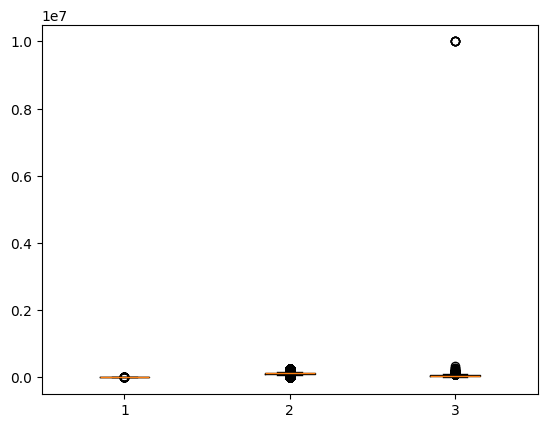

In [144]:
plt.boxplot(df[["Age","Monthly_Sales","Salary"]])
plt.show()

In [156]:
Q1 = df["Age"].quantile(0.25)
Q3 = df["Age"].quantile(0.75)

IQR = Q3-Q1

lower = Q1-1.5*(IQR)
HIGER = Q3+1.5*(IQR)

a = df[(df["Age"]<lower) | (df["Age"]>HIGER)].index

In [157]:
df.drop(a,inplace=True)


In [158]:
df.shape

(9783, 20)

In [160]:
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error,mean_squared_error,root_mean_squared_error,r2_score
from sklearn.tree import DecisionTreeClassifier
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score

In [163]:
q1 = df["Monthly_Sales"].quantile(0.25)
q3 = df["Monthly_Sales"].quantile(0.75)

iqr = q3-q1

low = q1-1.5*(iqr)
high = q3+1.5*(iqr)

df[(df["Monthly_Sales"]<low) | (df["Monthly_Sales"]>high)]

,Employee_ID,Full_Name,Age,Gender,Department,Job_Title,City,Education,Salary,Bonus,Joining_Date,Experience_Years,Performance_Rating,Projects_Completed,Remote_Work,Employment_Status,Email,Overtime_Hours,Monthly_Sales,Last_Review_Date
0,EMP13360,Ananya Patil,45.000000,Male,Hr,Developer,Pune,Master's,68660.0,8601,2019-12-11,13.1,2.000000,17.0,Hybrid,Resigned,employee3360@example.com,30.9,13306.58,2025-04-02
1,EMP19369,Ananya Patil,34.000000,Female,Finance,Developer,Delhi,Bachelor's,15629.0,699,2022-07-22,18.8,3.142909,0.0,Yes,INACTIVE,employee9369@example.com,33.3,30004.81,2025-03-10
4,EMP17380,Ananya Kulkarni,25.000000,Female,Support,Support Engineer,Nagpur,Diploma,51566.0,1997,2025-07-10,14.7,1.000000,29.0,Yes,On Leave,employee7380@example.com,33.2,224435.73,2026-06-29
10,EMP10433,Neha Joshi,27.000000,Other,Finance,Executive,Nashik,Bachelor's,39164.0,5464,2025-07-08,6.5,2.000000,27.0,Hybrid,Active,employee433@example.com,0.2,42933.84,2026-05-04
16,EMP10710,Ananya Patil,44.000000,Male,Support,Analyst,Nashik,Phd,58602.0,2379,2018-12-05,9.6,3.142909,0.0,no,Resigned,employee710@example.com,38.4,192839.92,2025-11-07
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10108,EMP18369,Aarav Joshi,29.000000,Male,Operations,Executive,pune,Phd,30941.0,2752,2025-01-24,14.0,3.142909,18.0,YES,Resigned,employee8369@example.com,33.4,70200.75,2026-01-12
10109,EMP10450,Priya Khan,31.850353,Male,Hr,Accountant,MUMBAI,High school,32285.0,3326,2023-12-31,21.8,3.142909,27.0,no,Resigned,employee450@example.com,37.2,243318.12,2025-06-16
10112,EMP13458,Rahul Sharma,40.000000,Male,Marketing,Analyst,Nashik,Master's,26142.0,3290,2023-12-31,3.3,1.000000,12.0,No,Resigned,employee3458@example.com,33.1,52703.37,2025-11-05
10115,EMP17891,Vikram Kulkarni,28.000000,Other,Finance,Intern,pune,Bachelor's,44946.0,4892,2020-08-27,23.1,3.000000,8.0,no,Resigned,employee7891@example.com,19.9,210149.96,2025-02-07


In [164]:
df.shape

(9783, 20)

In [165]:
num_cols = df.select_dtypes(include="number").columns

for col in num_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    count = ((df[col] < lower) | (df[col] > upper)).sum()

    print(col, ":", count)

Age : 0
Salary : 365
Bonus : 365
Experience_Years : 8
Performance_Rating : 1126
Projects_Completed : 0
Overtime_Hours : 0
Monthly_Sales : 3448


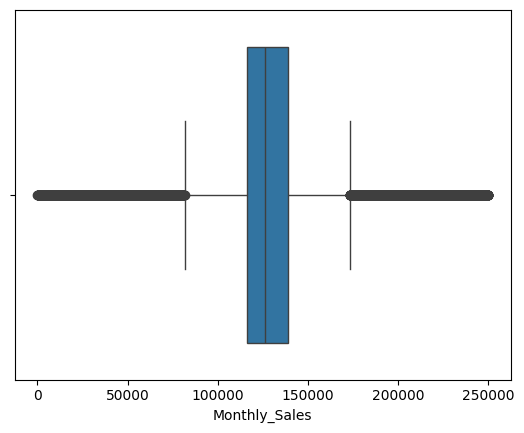

In [166]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.boxplot(x=df["Monthly_Sales"])
plt.show()